installing from requirements yields an error just like in the other 2 tasks so i'm forced to install the latest versions.

In [9]:
import sys

import numpy
import pandas
import sklearn
import matplotlib

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.15.0 2.5.4 3.0.6 1.9.1 3.11.2


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2666
np.random.seed(SEED)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (32940, 22)
Test shape: (8236, 20)


In [11]:
train.head()

,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


## Stage 1 — Frame the problem

1. What exactly is predicted, for whom, and when is the score computed?
2. What does the 10 % capacity change about the metric? (restate the business question in your own words, name the metric and why)
3. Which columns differ between train.csv and test.csv, why, and what does that mean for the model?

In [12]:
only_train = [c for c in train.columns if c not in test.columns]
only_test = [c for c in test.columns if c not in train.columns]
print("only in train:", only_train)
print("only in test:", only_test)
print("ids shared by train and test:", len(set(train["id"]) & set(test["id"])))

only in train: ['duration', 'y']
only in test: []
ids shared by train and test: 0


In [13]:
y = (train["y"] == "yes").astype(int)
base_rate = y.mean()

n_calls = int(np.ceil(0.10 * len(test)))
expected_yes = base_rate * len(test)
perfect_precision = min(1.0, expected_yes / n_calls)

print(f"Base rate (yes in train): {base_rate:.4f}")
print(f"Clients that can be called in {len(test)} rows: {n_calls}")
print(f"Calling at random: about {base_rate * n_calls:.0f} yes-clients, precision {base_rate:.3f}")
print(f"Yes-clients expected in the whole wave: about {expected_yes:.0f}")
print(f"Perfect ranking: precision {perfect_precision:.2f}, recall {min(1.0, n_calls / expected_yes):.2f}, lift {perfect_precision / base_rate:.1f}")

Base rate (yes in train): 0.1127
Clients that can be called in 8236 rows: 824
Calling at random: about 93 yes-clients, precision 0.113
Yes-clients expected in the whole wave: about 928
Perfect ranking: precision 1.00, recall 0.89, lift 8.9


Answers:

1.

2.

3.

## Stage 2 — Understand the data

### 2.1 Class balance

,rows,share
y,,
no,29229,0.8873
yes,3711,0.1127


always answering 'no' gives accuracy 0.8873


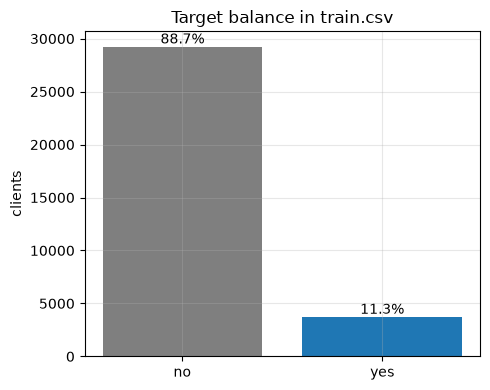

In [14]:
counts = train["y"].value_counts()
share = train["y"].value_counts(normalize=True)
display(pd.DataFrame({"rows": counts, "share": share.round(4)}))
print(f"always answering 'no' gives accuracy {share['no']:.4f}")

plt.figure(figsize=(5, 4))
plt.bar(counts.index, counts.values, color=["tab:gray", "tab:blue"])
for i, label in enumerate(counts.index):
    plt.text(i, counts[label], f"{share[label]:.1%}", ha="center", va="bottom")
plt.ylabel("clients")
plt.title("Target balance in train.csv")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.2 "Missing" and "not applicable" values

In [15]:
cat_cols = train.drop(columns="y").select_dtypes(exclude="number").columns.tolist()
num_cols = train.drop(columns=["y", "id"]).select_dtypes(include="number").columns.tolist()

unknown = pd.DataFrame({
    "train": (train[cat_cols] == "unknown").sum(),
    "test": (test[cat_cols] == "unknown").sum(),
})
unknown["train_%"] = (unknown["train"] / len(train) * 100).round(2)
unknown["test_%"] = (unknown["test"] / len(test) * 100).round(2)
display(unknown[unknown["train"] > 0].sort_values("train", ascending=False))

print("real NaN cells (train, test):", train.isna().sum().sum(), test.isna().sum().sum())
print("train rows with at least one 'unknown':", (train[cat_cols] == "unknown").any(axis=1).sum())
print("housing and loan are unknown on the same rows:", ((train["housing"] == "unknown") == (train["loan"] == "unknown")).all())

,train,test,train_%,test_%
default,6871,1725,20.86,20.94
education,1401,329,4.25,3.99
housing,794,196,2.41,2.38
loan,794,196,2.41,2.38
job,275,55,0.83,0.67
marital,64,16,0.19,0.19


real NaN cells (train, test): 0 0
train rows with at least one 'unknown': 8582
housing and loan are unknown on the same rows: True


pdays == 999 in train: 31694 (96.2%) | in test: 7967 (96.7%)
largest real pdays in train: 25


poutcome,failure,nonexistent,success
pdays == 999,,,
False,116,0,1130
True,3248,28446,0


previous == 0,False,True
pdays == 999,,
False,1246,0
True,3248,28446


yes-rate by pdays == 999:
pdays
False    0.636
True     0.092
Name: y, dtype: float64


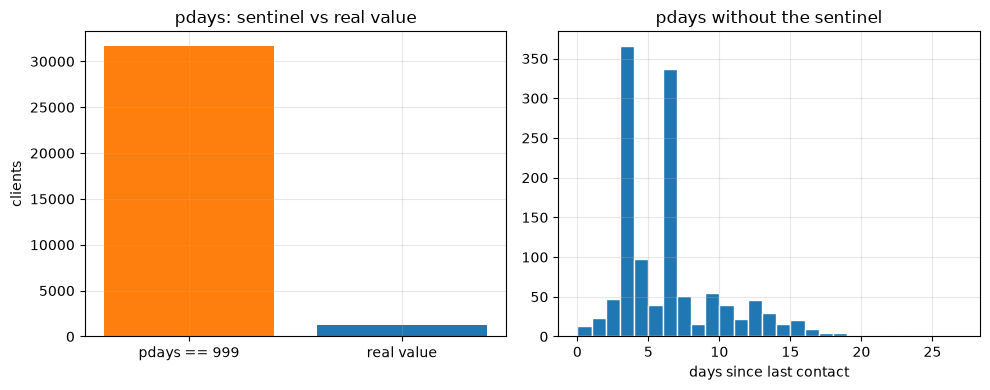

count    1246.00
mean        5.93
std         3.69
min         0.00
25%         3.00
50%         6.00
75%         7.00
max        25.00
Name: pdays, dtype: float64


In [16]:
is_sent = train["pdays"] == 999
print("pdays == 999 in train:", is_sent.sum(), f"({is_sent.mean():.1%})", "| in test:", (test["pdays"] == 999).sum(), f"({(test['pdays'] == 999).mean():.1%})")
print("largest real pdays in train:", train.loc[~is_sent, "pdays"].max())

display(pd.crosstab(is_sent, train["poutcome"], rownames=["pdays == 999"]))
display(pd.crosstab(is_sent, train["previous"] == 0, rownames=["pdays == 999"], colnames=["previous == 0"]))

print("yes-rate by pdays == 999:")
print(train["y"].eq("yes").groupby(is_sent).mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(["pdays == 999", "real value"], [is_sent.sum(), (~is_sent).sum()], color=["tab:orange", "tab:blue"])
axes[0].set_ylabel("clients")
axes[0].set_title("pdays: sentinel vs real value")
axes[1].hist(train.loc[~is_sent, "pdays"], bins=range(0, 28), color="tab:blue", edgecolor="white")
axes[1].set_xlabel("days since last contact")
axes[1].set_title("pdays without the sentinel")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(train.loc[~is_sent, "pdays"].describe().round(2))

### 2.3 Row order

In [17]:
ids = train["id"].to_numpy()
print("id strictly increasing:", np.all(np.diff(ids) > 0), "| train ids", ids.min(), "-", ids.max(), "| test ids", test["id"].min(), "-", test["id"].max())

# in calendar order neighbouring rows would almost always share a month
months = train["month"].to_numpy()
observed = (months[1:] != months[:-1]).mean()
expected = 1 - (train["month"].value_counts(normalize=True) ** 2).sum()
print(f"neighbouring rows with a different month: {observed:.3f} (random shuffle would give about {expected:.3f})")

decile = pd.qcut(train["id"], 10, labels=False)
print("yes-rate by id decile:")
print(y.groupby(decile).mean().round(3).to_string())
print("correlation of id with the macro columns:")
print(train[["id", "emp.var.rate", "euribor3m", "nr.employed"]].corr()["id"].drop("id").round(4))

id strictly increasing: True | train ids 0 - 32939 | test ids 32940 - 41175
neighbouring rows with a different month: 0.803 (random shuffle would give about 0.805)
yes-rate by id decile:
id
0    0.108
1    0.118
2    0.111
3    0.113
4    0.105
5    0.115
6    0.109
7    0.116
8    0.114
9    0.117
correlation of id with the macro columns:
emp.var.rate    0.0018
euribor3m       0.0020
nr.employed    -0.0001
Name: id, dtype: float64


### 2.4 Which features look related to the answer, and by how much?

Categorical columns: information gain of `y` (the same entropy idea as in Task 2), as a share of the entropy of `y`.
Numeric columns: ROC-AUC of the column used alone as a score (0.5 means no signal). Information gain leans towards columns with many levels, so read it together with the yes-rate plot below.

In [18]:
def entropy(labels):
    """Entropy in bits of an array of integer class labels."""
    _, counts = np.unique(labels, return_counts=True)
    p = counts / len(labels)
    return -np.sum(p * np.log2(p))


def info_gain(feature, labels):
    """Entropy of the labels minus the weighted entropy inside each level of the feature."""
    weighted = sum(
        (feature == level).mean() * entropy(labels[feature == level])
        for level in feature.unique()
    )
    return entropy(labels) - weighted


h = entropy(y)
gains = pd.Series({c: info_gain(train[c], y) for c in cat_cols}).sort_values(ascending=False)
print(f"entropy of y: {h:.3f} bits")
display(pd.DataFrame({"gain_bits": gains.round(4), "share_of_H": (gains / h).round(3)}))

entropy of y: 0.508 bits


,gain_bits,share_of_H
poutcome,0.0445,0.088
month,0.0378,0.074
contact,0.0166,0.033
job,0.0137,0.027
default,0.0082,0.016
education,0.0035,0.007
marital,0.0019,0.004
day_of_week,0.0005,0.001
housing,0.0001,0.000
loan,0.0000,0.000


In [19]:
from sklearn.metrics import roc_auc_score

rows = []
for c in num_cols:
    auc = roc_auc_score(y, train[c])
    rows.append({
        "feature": c,
        "auc_alone": auc,
        "distance_from_0.5": abs(auc - 0.5),
        "mean_if_no": train.loc[y == 0, c].mean(),
        "mean_if_yes": train.loc[y == 1, c].mean(),
        "in_test": c in test.columns,
    })

num_df = pd.DataFrame(rows).set_index("feature").sort_values("distance_from_0.5", ascending=False)
display(num_df.round(3))

,auc_alone,distance_from_0.5,mean_if_no,mean_if_yes,in_test
feature,,,,,
duration,0.818,0.318,220.281,552.161,False
nr.employed,0.250,0.250,5176.201,5094.769,True
euribor3m,0.255,0.245,3.812,2.119,True
emp.var.rate,0.283,0.217,0.250,-1.236,True
previous,0.610,0.110,0.133,0.498,True
cons.price.idx,0.391,0.109,93.603,93.358,True
pdays,0.401,0.099,983.611,786.776,True
campaign,0.447,0.053,2.616,2.052,True
cons.conf.idx,0.542,0.042,-40.596,-39.742,True


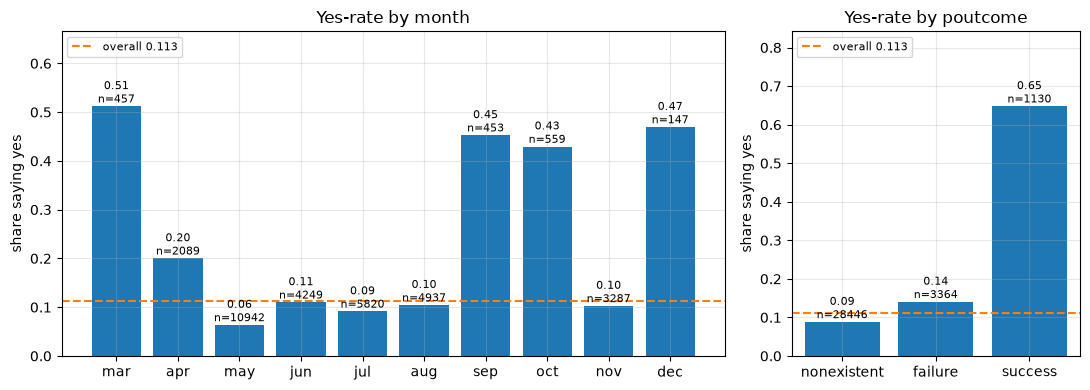

In [20]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
poutcome_order = ["nonexistent", "failure", "success"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2.3, 1]})
for ax, col, order in [(axes[0], "month", month_order), (axes[1], "poutcome", poutcome_order)]:
    g = y.groupby(train[col]).agg(["mean", "size"]).loc[order]
    ax.bar(g.index, g["mean"], color="tab:blue")
    ax.axhline(base_rate, color="tab:orange", linestyle="--", label=f"overall {base_rate:.3f}")
    for i, (rate, n) in enumerate(g[["mean", "size"]].to_numpy()):
        ax.text(i, rate, f"{rate:.2f}\nn={int(n)}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, g["mean"].max() * 1.3)
    ax.set_ylabel("share saying yes")
    ax.set_title(f"Yes-rate by {col}")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Answers:

- Imbalance and the always-"no" accuracy:

- Missing / not applicable (which columns, how many):

- Row order, what it could mean, and whether the split in Stage 3 has to respect it:

- Features most related to y, by how much, and which of them can actually be used:

## Stage 3 — Design the validation

In [21]:
from sklearn.model_selection import train_test_split, StratifiedKFold

feature_cols = [c for c in test.columns if c != "id"]   # exactly what test.csv offers
X = train[feature_cols]
y = (train["y"] == "yes").astype(int)

HOLDOUT = 0.2
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=HOLDOUT, stratify=y, random_state=SEED
)

n_calls_hold = int(np.ceil(0.10 * len(y_hold)))
print("dev:", X_dev.shape, "| hold-out:", X_hold.shape)
print("yes-rate dev / hold-out:", round(y_dev.mean(), 4), round(y_hold.mean(), 4))
print("yes-clients in hold-out:", y_hold.sum(), "| clients called under the 10 % rule:", n_calls_hold)
for p in (0.3, 0.5):
    print(f"if precision in the top 10 % is {p}: standard error on the hold-out = {np.sqrt(p * (1 - p) / n_calls_hold):.3f}")

dev: (26352, 19) | hold-out: (6588, 19)
yes-rate dev / hold-out: 0.1127 0.1126
yes-clients in hold-out: 742 | clients called under the 10 % rule: 659
if precision in the top 10 % is 0.3: standard error on the hold-out = 0.018
if precision in the top 10 % is 0.5: standard error on the hold-out = 0.019


In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

folds = []
for i, (fit_idx, val_idx) in enumerate(cv.split(X_dev, y_dev), start=1):
    folds.append({
        "fold": i,
        "fit_rows": len(fit_idx),
        "val_rows": len(val_idx),
        "val_yes": int(y_dev.iloc[val_idx].sum()),
        "val_yes_rate": y_dev.iloc[val_idx].mean(),
    })
display(pd.DataFrame(folds).round(4))

,fold,fit_rows,val_rows,val_yes,val_yes_rate
0,1,21081,5271,594,0.1127
1,2,21081,5271,594,0.1127
2,3,21082,5270,593,0.1125
3,4,21082,5270,594,0.1127
4,5,21082,5270,594,0.1127


In [23]:
def precision_at_10(estimator, X, y_true):
    """Share of yes-clients among the 10 % of clients with the highest score."""
    if hasattr(estimator, "predict_proba"):
        score = estimator.predict_proba(X)[:, 1]
    else:
        score = estimator.decision_function(X)
    y_true = np.asarray(y_true)
    k = int(np.ceil(0.10 * len(y_true)))
    top = np.argsort(-score, kind="stable")[:k]
    return y_true[top].mean()


scoring = {
    "roc_auc": "roc_auc",
    "avg_precision": "average_precision",
    "precision_at_10": precision_at_10,
}

## Stage 4 — Preprocess inside a pipeline

In [24]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols and c != "pdays"]


def make_prep(pdays="flag", unknown="category"):
    """pdays: 'raw' | 'flag' (999 -> median of the real values + a 0/1 flag) | 'drop'.
    unknown: 'category' (keep as its own level) | 'mode' (replace by the most frequent level)."""
    blocks = [("num", StandardScaler(), num_cols + (["pdays"] if pdays == "raw" else []))]
    if pdays == "flag":
        blocks.append(("pdays", make_pipeline(
            SimpleImputer(missing_values=999, strategy="median", add_indicator=True),
            StandardScaler()), ["pdays"]))

    cat_steps = []
    if unknown == "mode":
        cat_steps.append(SimpleImputer(missing_values="unknown", strategy="most_frequent"))
    cat_steps.append(OneHotEncoder(handle_unknown="ignore"))
    blocks.append(("cat", make_pipeline(*cat_steps), cat_cols))
    return ColumnTransformer(blocks)

In [25]:
fit_idx, val_idx = next(iter(cv.split(X_dev, y_dev)))
X_fit, y_fit = X_dev.iloc[fit_idx], y_dev.iloc[fit_idx]

check = Pipeline([("prep", make_prep()), ("clf", LogisticRegression(max_iter=2000))]).fit(X_fit, y_fit)
prep = check.named_steps["prep"]
scaler = prep.named_transformers_["num"]
pdays_imp = prep.named_transformers_["pdays"].steps[0][1]
i = num_cols.index("age")

print("scaler mean for age       :", round(scaler.mean_[i], 5))
print("mean of age, fit rows only:", round(X_fit["age"].mean(), 5))
print("mean of age, all dev rows :", round(X_dev["age"].mean(), 5))
print("pdays median learned      :", pdays_imp.statistics_[0], "| median of real pdays in fit rows:", X_fit.loc[X_fit["pdays"] != 999, "pdays"].median())

scaler mean for age       : 40.04279
mean of age, fit rows only: 40.04279
mean of age, all dev rows : 40.01882
pdays median learned      : 6.0 | median of real pdays in fit rows: 6.0


In [26]:
variants = {
    "pdays raw, unknown = own level": dict(pdays="raw", unknown="category"),
    "pdays 999 -> median + flag, unknown = own level": dict(pdays="flag", unknown="category"),
    "pdays dropped, unknown = own level": dict(pdays="drop", unknown="category"),
    "pdays flag, unknown -> most frequent": dict(pdays="flag", unknown="mode"),
}

rows, auc_folds = [], {}
for name, opts in variants.items():
    model = Pipeline([("prep", make_prep(**opts)), ("clf", LogisticRegression(max_iter=2000))])
    res = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring)
    auc_folds[name] = res["test_roc_auc"]
    row = {"variant": name}
    for m in scoring:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"] = res[f"test_{m}"].std()
    rows.append(row)
display(pd.DataFrame(rows).set_index("variant").round(4))

base_name = list(variants)[0]
print("per-fold ROC-AUC difference against:", base_name)
for name, s in auc_folds.items():
    d = s - auc_folds[base_name]
    print(f"{name}: mean {d.mean():+.4f} | folds {np.round(d, 4)}")

,roc_auc_mean,roc_auc_std,avg_precision_mean,avg_precision_std,precision_at_10_mean,precision_at_10_std
variant,,,,,,
"pdays raw, unknown = own level",0.7934,0.0166,0.4521,0.0224,0.5002,0.0126
"pdays 999 -> median + flag, unknown = own level",0.7934,0.0167,0.4517,0.0235,0.4975,0.0155
"pdays dropped, unknown = own level",0.7929,0.0165,0.4507,0.0212,0.4960,0.0146
"pdays flag, unknown -> most frequent",0.7935,0.0156,0.4512,0.0234,0.5017,0.0145


per-fold ROC-AUC difference against: pdays raw, unknown = own level
pdays raw, unknown = own level: mean +0.0000 | folds [0. 0. 0. 0. 0.]
pdays 999 -> median + flag, unknown = own level: mean -0.0000 | folds [ 0.      0.0002  0.0002 -0.0007  0.0002]
pdays dropped, unknown = own level: mean -0.0005 | folds [-0.0008 -0.0004 -0.0002 -0.0009 -0.    ]
pdays flag, unknown -> most frequent: mean +0.0001 | folds [ 0.0002  0.0028 -0.0023 -0.0016  0.0012]


In [27]:
chosen = dict(pdays="flag", unknown="category")   # change this to what your table supports
pipe = Pipeline([("prep", make_prep(**chosen)), ("clf", LogisticRegression(max_iter=2000))])
pipe.fit(X_dev, y_dev)

raw_test = test[feature_cols]
scores_test = pipe.predict_proba(raw_test)[:, 1]
print(raw_test.shape, scores_test.shape, scores_test[:3].round(3))

(8236, 19) (8236,) [0.071 0.035 0.045]


In [28]:
for c in ["default", "education", "job"]:
    display(y_dev.groupby(X_dev[c]).agg(["mean", "size"]).round(3))

,mean,size
default,,
no,0.129,20891
unknown,0.051,5459
yes,0.000,2


,mean,size
education,,
basic.4y,0.100,2690
basic.6y,0.085,1428
basic.9y,0.077,3871
high.school,0.110,6017
illiterate,0.333,12
professional.course,0.111,3337
university.degree,0.137,7858
unknown,0.147,1139


,mean,size
job,,
admin.,0.132,6712
blue-collar,0.072,5912
entrepreneur,0.075,963
housemaid,0.091,693
management,0.113,1854
retired,0.256,1117
self-employed,0.105,875
services,0.081,2538
student,0.313,556


## Stage 5 — Baselines

In [30]:
from sklearn.dummy import DummyClassifier

scoring_all = {**scoring, "accuracy": "accuracy"}
cv_results = {}   # model name -> per-fold scores, reused in Stage 6


def run_cv(name, model):
    res = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring_all)
    cv_results[name] = {m: res[f"test_{m}"] for m in scoring_all}


def summary_table():
    rows = []
    for name, folds in cv_results.items():
        row = {"model": name}
        for m, v in folds.items():
            row[m] = f"{v.mean():.4f} ± {v.std():.4f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


baselines = {
    "majority class": Pipeline([("prep", make_prep(**chosen)), ("clf", DummyClassifier(strategy="prior"))]),
    "logistic regression": Pipeline([("prep", make_prep(**chosen)), ("clf", LogisticRegression(max_iter=2000))]),
}
for name, model in baselines.items():
    run_cv(name, model)

display(summary_table())

,roc_auc,avg_precision,precision_at_10,accuracy
model,,,,
majority class,0.5000 ± 0.0000,0.1127 ± 0.0001,0.1141 ± 0.0111,0.8873 ± 0.0001
logistic regression,0.7934 ± 0.0167,0.4517 ± 0.0235,0.4975 ± 0.0155,0.8990 ± 0.0022


In [31]:
print("per-fold ROC-AUC:")
display(pd.DataFrame({n: f["roc_auc"] for n, f in cv_results.items()}).round(4))
print("per-fold precision in the top 10 %:")
display(pd.DataFrame({n: f["precision_at_10"] for n, f in cv_results.items()}).round(4))
for n, f in cv_results.items():
    print(f"{n}: lift in the top 10 % = {f['precision_at_10'].mean() / y_dev.mean():.2f}")

per-fold ROC-AUC:


,majority class,logistic regression
0,0.5,0.8159
1,0.5,0.7749
2,0.5,0.8109
3,0.5,0.7836
4,0.5,0.7817


per-fold precision in the top 10 %:


,majority class,logistic regression
0,0.1098,0.5133
1,0.1269,0.4981
2,0.1214,0.5161
3,0.1176,0.4801
4,0.0949,0.4801


majority class: lift in the top 10 % = 1.01
logistic regression: lift in the top 10 % = 4.42


## Stage 6 — Compare models and tune

## Stage 7 — Final evaluation

## Stage 8 — Save and describe the model